## EpiSurge : Modelling & Evaluation

## 1. Setup




In [ ]:
import importlib.util, subprocess, sys

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if importlib.util.find_spec("epiweeks") is None:
    _pip("epiweeks==2.4.0")
if importlib.util.find_spec("chronos") is None:
    try:   # --no-deps: never let it swap Colab's preinstalled torch / transformers / pandas
        _pip("--no-deps", "chronos-forecasting==2.2.2", "einops==0.8.1")
    except Exception as e:                      # Chronos is one baseline; the rest still runs
        print("Chronos install failed, that baseline will be skipped:", e)

import hashlib, json, math, os, time, warnings, zipfile
from pathlib import Path
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # deterministic cuBLAS (must precede CUDA init)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import lightgbm as lgb
import statsmodels.api as sm
from scipy.spatial.distance import jensenshannon
from scipy.stats import spearmanr
from epiweeks import Week

warnings.filterwarnings("ignore", category=FutureWarning)
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")   # Windows consoles default to cp1252 (no σ, Δ, ρ)
# GPU (Colab T4) should be faster for the GRU/LSTM; CPU works too (~85 min measured). GPU path not
# benchmarked — if it misbehaves, set DEVICE = "cpu".
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.use_deterministic_algorithms(True, warn_only=DEVICE == "cuda")   # a few CUDA kernels have no deterministic version
torch.backends.cudnn.benchmark = False
print("device:", DEVICE)

def set_seed(s):
    import random
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

print("torch", torch.__version__, "| pandas", pd.__version__, "| lightgbm", lgb.__version__)

device: cuda
torch 2.11.0+cu130 | pandas 2.2.3 | lightgbm 4.6.0


## 2. Config

In [ ]:
HORIZONS = [1, 2, 3, 4, 6, 8]          # frozen scope; target = final wILI of week T+h  (D1)
H = len(HORIZONS)
REGIONS = list(range(1, 11))
N_NODES = 10
SEASONS = {"2019-20": (201927, 202026), "2022-23": (202227, 202326), "2023-24": (202327, 202426)}
FOLDS = {"F1": (["2019-20"], "2022-23"),               # train -> test, strictly forward in time
         "F2": (["2019-20", "2022-23"], "2023-24")}    # F2 = primary result
COVID_MASK = (202011, 202226)   # D3: training targets in this range are COVID-era ILI, masked

SHRINK_K = 5                    # empirical-Bayes strength, same as Phase 1 (F11)
TOPK = 3                        # neighbours kept per node per relation
RELATIONS = ["gravity", "climate", "genomic"]

QUICK = os.environ.get("EPISURGE_QUICK") == "1"     # fast smoke-test mode, not for results
SEEDS = [0] if QUICK else [0, 1, 2, 3, 4]
EPOCHS = 15 if QUICK else 200                        # D4: fixed recipe, no early stopping
LR, WD, BATCH, DROPOUT, CLIP = 1e-3, 1e-3, 16, 0.2, 1.0
HIDDEN, GRAPH_OUT, TFT_D = 64, 32, 16
N_BOOT = 200 if QUICK else 2000
N_PERM = 50 if QUICK else 1000
BLOCK = 4                                            # bootstrap block length (weeks)
WIS_ALPHAS = [0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # FluSight 23 quantiles
CONFIG = {k: v for k, v in dict(globals()).items() if k.isupper() and isinstance(v, (int, float, str, list, dict, tuple))}


## 3. Data

In [ ]:
# if "google.colab" in sys.modules:
#     from google.colab import drive
#     drive.mount("/content/drive")
#     BASE = Path("/content")
# else:
#     BASE = Path(os.environ.get("EPISURGE_BASE", "."))

FILES = {
    "master": "/content/drive/MyDrive/EpiSurge-Master/data/processed/master_region_week.csv",
    "fluview": "/content/drive/MyDrive/EpiSurge-Master/data/raw/fluview/fluview.csv",
    "vintages": "/content/drive/MyDrive/EpiSurge-Master/data/raw/fluview/fluview_vintages.csv",
    "population": "/content/drive/MyDrive/EpiSurge-Master/data/raw/census/hhs_region_population.csv",
}
# zip_path = BASE / "data.zip"

# # Safely extract or download/copy the zip file if it's missing or invalid
# if zip_path.exists() and not (BASE / FILES["master"]).exists():
#     try:
#         with zipfile.ZipFile(zip_path) as zf:
#             zf.extractall(BASE)
#     except zipfile.BadZipFile:
#         print("Warning: /content/data.zip is corrupted or not a valid zip file.")
#         print("Please make sure you have placed the correct 'data.zip' in /content/.")

# missing = [p for p in FILES.values() if not (BASE / p).exists()]
# if missing:
#     print(f"Missing input files under {BASE}: {missing}")
#     print("Attempting to copy data.zip from Google Drive if available...")
#     # Check standard Google Drive locations for the project
#     gdrive_candidate = Path("/content/data.zip")
#     if gdrive_candidate.exists():
#         import shutil
#         shutil.copy(gdrive_candidate, zip_path)
#         with zipfile.ZipFile(zip_path) as zf:
#             zf.extractall(BASE)
#         missing = [p for p in FILES.values() if not (BASE / p).exists()]


# RESULTS = BASE / "results" / ("phase3_quick" if QUICK else "phase3")
# FIGS = RESULTS / "figures"
# FIGS.mkdir(parents=True, exist_ok=True)
# INPUT_MD5 = {k: hashlib.md5((BASE / p).read_bytes()).hexdigest() for k, p in FILES.items()}
# print("Inputs OK:", INPUT_MD5)

## 4. Load & verify data

In [ ]:
m = pd.read_csv(FILES["master"])
fv = pd.read_csv(FILES["fluview"])
fv["hhs_region"] = fv["region"].str.replace("hhs", "").astype(int)
pop = pd.read_csv(FILES["population"]).sort_values("hhs_region").reset_index(drop=True)

core = m[m["in_core_season"]]
assert m.shape == (1560, 43) and len(core) == 990, m.shape
assert (core.groupby("season").size() == 330).all()
cov = core.groupby("season")[["has_genomic_oracle", "has_genomic_asof_L8_16", "has_genomic_asof_L4_12"]].mean().mean() * 100
assert np.allclose(cov.values, [73.9, 60.3, 55.8], atol=0.06), cov
assert core[["wili_final", "population", "abs_humidity"]].notna().all().all() and core["has_surveillance"].all()

# timing convention: lag1 at row T is week T-1 as published at T (not week T)
_s = m.sort_values(["hhs_region", "epiweek"])
_prev = _s.groupby(["hhs_region", "season"])["wili_final"].shift(1)
assert (_s["ili_asof_lag1"] - _prev).abs().median() < 0.05
assert (_s["ili_asof_lag1"] - _s["wili_final"]).abs().median() > 0.1
print("Phase 1 outputs verified. Core-season genomic coverage (%):", cov.round(1).to_dict())


Phase 1 outputs verified. Core-season genomic coverage (%): {'has_genomic_oracle': 73.9, 'has_genomic_asof_L8_16': 60.3, 'has_genomic_asof_L4_12': 55.8}


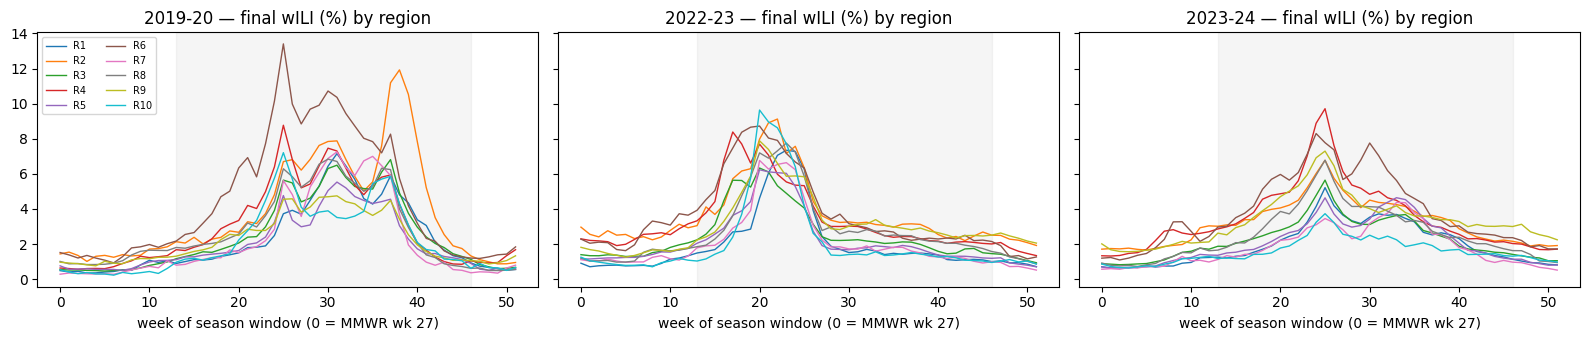

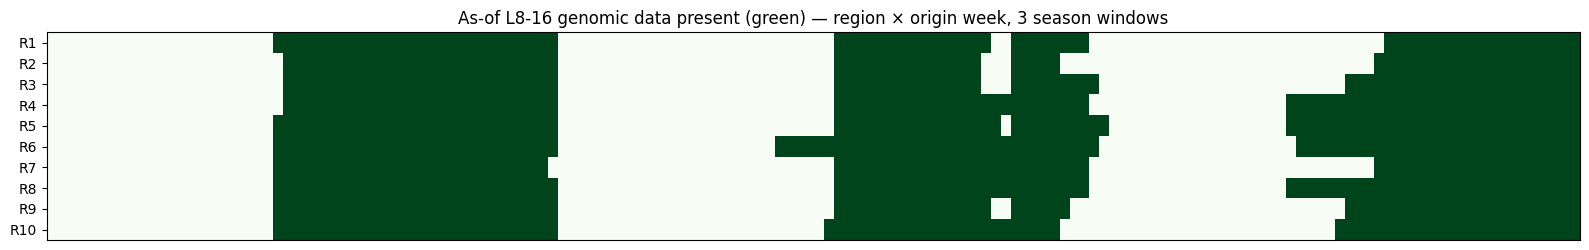

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5), sharey=True)
for ax, (s, g) in zip(axes, m.groupby("season")):
    for r, gr in g.groupby("hhs_region"):
        ax.plot(range(len(gr)), gr["wili_final"], lw=1, label=f"R{r}")
    ax.set_title(f"{s} — final wILI (%) by region"); ax.set_xlabel("week of season window (0 = MMWR wk 27)")
    ax.axvspan(13, 46, color="grey", alpha=0.08)   # core season wk 40-20
axes[0].legend(ncol=2, fontsize=7); plt.tight_layout(); plt.savefig(FIGS / "wili_by_region.png", dpi=120); plt.show()

hm = m.pivot(index="hhs_region", columns="epiweek", values="has_genomic_asof_L8_16").astype(float)
plt.figure(figsize=(16, 2.6)); plt.imshow(hm, aspect="auto", cmap="Greens", interpolation="nearest")
plt.yticks(range(10), [f"R{r}" for r in hm.index]); plt.xticks([])
plt.title("As-of L8-16 genomic data present (green) — region × origin week, 3 season windows")
plt.tight_layout(); plt.savefig(FIGS / "genomic_coverage.png", dpi=120); plt.show()


## 6. Targets — y(T+h) from final FluView, COVID mask

In [ ]:
def ew_add(ew, k):
    w = Week(ew // 100, ew % 100) + k
    return w.year * 100 + w.week

assert ew_add(202052, 1) == 202053 and ew_add(202053, 1) == 202101 and ew_add(202301, -1) == 202252

final = fv.set_index(["hhs_region", "epiweek"])["wili"]
P = m.sort_values(["epiweek", "hhs_region"]).reset_index(drop=True)   # row order = (origin, region)
P["T"] = P["epiweek"]
for h in HORIZONS:
    P[f"tw_{h}"] = P["T"].map(lambda t, h=h: ew_add(t, h))
    P[f"y_{h}"] = final.reindex(pd.MultiIndex.from_arrays([P["hhs_region"], P[f"tw_{h}"]])).to_numpy()
    P[f"covid_{h}"] = P[f"tw_{h}"].between(*COVID_MASK)
P["base"] = np.log1p(P["ili_asof_lag1"])
assert P[[f"y_{h}" for h in HORIZONS]][P["in_core_season"]].notna().all().all()
print("COVID-masked target cells:", int(sum(P[f"covid_{h}"].sum() for h in HORIZONS)))

COVID-masked target cells: 1200


## 7. Features - surveillance sequence, climate (T-1), static, season timing, genomic variants

In [ ]:
LAG_COLS = [f"ili_asof_lag{k}" for k in range(8, 0, -1)]
clim = m.set_index(["hhs_region", "epiweek"])[["temp_c", "abs_humidity"]]
prev = P["T"].map(lambda t: ew_add(t, -1))
P[["temp_tm1", "ah_tm1"]] = clim.reindex(pd.MultiIndex.from_arrays([P["hhs_region"], prev])).to_numpy()
P["log_pop"] = np.log(P["population"])
P["season_sin"] = np.sin(2 * np.pi * (P["T"] % 100) / 52.18)      # D2: in every model
P["season_cos"] = np.cos(2 * np.pi * (P["T"] % 100) / 52.18)
STATIC_BASE = ["temp_tm1", "ah_tm1", "log_pop", "season_sin", "season_cos"]
SUB = ["h1n1", "h3n2", "other"]
SRC = {"asof_L8_16": "asof_L8_16", "asof_L4_12": "asof_L4_12", "zero_fill": "asof_L8_16",
       "none": "asof_L8_16", "oracle": "oracle"}


def shrunk_composition(src):
    """EB-shrunk shares toward the pooled national composition at each origin; n=0 -> pooled."""
    n = P[f"{src}_n_total"].fillna(0)
    props = P[[f"{src}_prop_{s}" for s in SUB]].set_axis(SUB, axis=1)
    has = props.notna().all(axis=1) & (n > 0)
    n = n.where(has, 0)
    counts = props.mul(n, axis=0).fillna(0)
    pool = counts.groupby(P["T"]).transform("sum")
    pool = pool.div(pool.sum(axis=1).replace(0, np.nan), axis=0).fillna(1 / 3)
    shr = (counts + SHRINK_K * pool).div(n + SHRINK_K, axis=0)
    return shr, n, has


# self-check: recomputed shrinkage must match the Phase 1 stored values
for src in ["asof_L8_16", "asof_L4_12"]:
    shr, _, has = shrunk_composition(src)
    stored = P.loc[has, [f"{src}_shrunk_{s}" for s in SUB]].to_numpy()
    err = np.abs(shr[has].to_numpy() - stored).max()
    assert err < 0.02, (src, err)


def genomic_features(variant):
    """Returns (feature DataFrame, graph shares, graph has-flag) for a genomic variant."""
    shr, n, has = shrunk_composition(SRC[variant])
    # shares sum to 1, so "other" is redundant as a feature; it is also exactly 0 all of 2019-20
    # and up to 0.33 in 2023-24, which would make it a huge out-of-range input. Graphs still use all 3.
    two = shr[["h1n1", "h3n2"]]
    if variant == "none":
        feats = pd.DataFrame(index=P.index)
    elif variant == "zero_fill":               # H3 test: absence treated as zero, no count / flag
        feats = two.where(has, 0).add_prefix("g_")
    else:
        feats = two.add_prefix("g_").assign(g_logn=np.log1p(n), g_flag=has.astype(float))
    return feats, shr.to_numpy(), has.to_numpy()


SEASON_OF = {T: s for s, (a, b) in SEASONS.items() for T in P["T"].unique() if a <= T <= b}
P["season_"] = P["T"].map(SEASON_OF)
print("Static features:", STATIC_BASE, "+ genomic block (0, 3 or 5 cols)")


Static features: ['temp_tm1', 'ah_tm1', 'log_pop', 'season_sin', 'season_cos'] + genomic block (0, 3 or 5 cols)


## 8. Graphs

/tmp/ipykernel_436/2037675570.py:27: RuntimeWarning: Mean of empty slice
  c = (c - np.nanmean(c, 1, keepdims=True)) / (np.nanstd(c, 1, keepdims=True) + 1e-9)   # per-origin z-score
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/tmp/ipykernel_436/2037675570.py:30: RuntimeWarning: All-NaN slice encountered
  sig2 = np.nanmedian(d2[:, off], axis=1)[:, None, None] + 1e-9


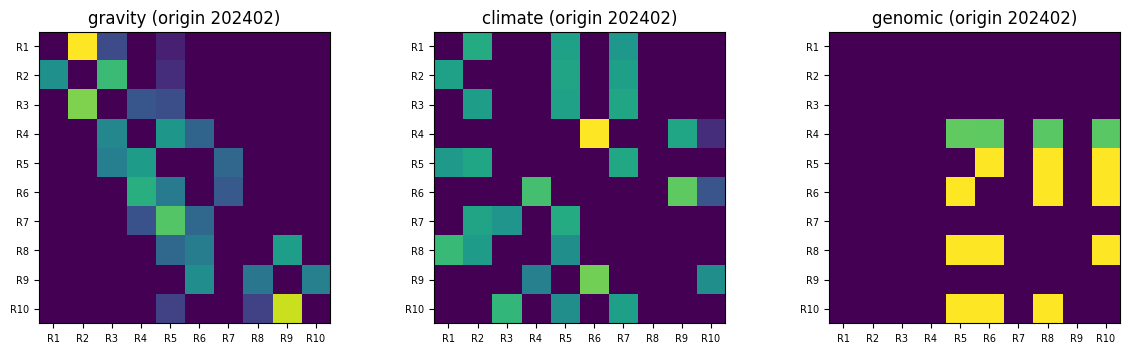

In [ ]:
ORIGINS = np.sort(P["T"].unique())
N_ORIG = len(ORIGINS)


def topk_norm(W, k=TOPK):
    W = W.copy()
    idx = np.arange(W.shape[-1]); W[..., idx, idx] = 0
    thr = np.sort(W, axis=-1)[..., -k][..., None]
    W = np.where((W >= thr) & (W > 0), W, 0.0)
    s = W.sum(-1, keepdims=True)
    return np.divide(W, s, out=np.zeros_like(W), where=s > 0)


def gravity_graph():
    lat, lon = np.radians(pop["centroid_lat"].to_numpy()), np.radians(pop["centroid_lon"].to_numpy())
    dlat, dlon = lat[:, None] - lat[None], lon[:, None] - lon[None]
    a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None]) * np.sin(dlon / 2) ** 2
    d = 2 * 6371 * np.arcsin(np.sqrt(a))
    p = pop["population"].to_numpy(float)
    with np.errstate(divide="ignore"):
        W = np.where(d > 0, np.outer(p, p) / d ** 2, 0)
    return topk_norm(W)


def climate_graphs():
    c = P[["temp_tm1", "ah_tm1"]].to_numpy().reshape(N_ORIG, N_NODES, 2)
    c = (c - np.nanmean(c, 1, keepdims=True)) / (np.nanstd(c, 1, keepdims=True) + 1e-9)   # per-origin z-score
    d2 = ((c[:, :, None] - c[:, None]) ** 2).sum(-1)
    off = ~np.eye(N_NODES, dtype=bool)
    sig2 = np.nanmedian(d2[:, off], axis=1)[:, None, None] + 1e-9
    return topk_norm(np.nan_to_num(np.exp(-d2 / sig2)))


def genomic_graphs(shares, has):
    p = shares.reshape(N_ORIG, N_NODES, 3); f = has.reshape(N_ORIG, N_NODES)
    W = np.zeros((N_ORIG, N_NODES, N_NODES))
    for t in range(N_ORIG):
        for i in range(N_NODES):
            for j in range(N_NODES):
                if i != j and f[t, i] and f[t, j]:
                    W[t, i, j] = 1 - jensenshannon(p[t, i], p[t, j], base=2) ** 2
    return topk_norm(W)


def random_graphs(seed):
    """Density-matched control: same out-degree (TOPK) per node, random neighbours, fixed per seed."""
    rng = np.random.default_rng(1000 + seed)
    A = np.zeros((len(RELATIONS), N_NODES, N_NODES))
    for r in range(len(RELATIONS)):
        for i in range(N_NODES):
            A[r, i, rng.choice([j for j in range(N_NODES) if j != i], TOPK, replace=False)] = 1 / TOPK
    return np.broadcast_to(A, (N_ORIG,) + A.shape).copy()


A_GRAV = gravity_graph()
A_CLIM = climate_graphs()
GRAPHS = {}   # genomic-source -> [N_ORIG, 3, 10, 10]
for src in ["asof_L8_16", "asof_L4_12", "oracle"]:
    _, shares, has = genomic_features(src)
    A_gen = genomic_graphs(shares, has)
    GRAPHS[src] = np.stack([np.broadcast_to(A_GRAV, A_gen.shape), A_CLIM, A_gen], 1).astype(np.float32)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
t_show = int(np.where(ORIGINS == 202402)[0][0])
for ax, r, name in zip(axes, range(3), RELATIONS):
    ax.imshow(GRAPHS["asof_L8_16"][t_show, r], cmap="viridis"); ax.set_title(f"{name} (origin 202402)")
    ax.set_xticks(range(10), [f"R{i}" for i in REGIONS], fontsize=7); ax.set_yticks(range(10), [f"R{i}" for i in REGIONS], fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "graphs_example.png", dpi=120); plt.show()


## 9. Fold builder + leakage guard

In [ ]:
def build_fold(fold, variant):
    train_seasons, test_season = FOLDS[fold]
    gfeat, _, _ = genomic_features(variant)
    stat_cols = STATIC_BASE + list(gfeat.columns)
    D = pd.concat([P, gfeat], axis=1)
    complete = D[LAG_COLS + stat_cols].notna().all(axis=1).groupby(D["T"]).transform("all")
    is_tr = D["season_"].isin(train_seasons) & complete
    is_te = (D["season_"] == test_season) & D["in_core_season"]
    first_test = D.loc[is_te, "T"].min()

    seq = np.log1p(D[LAG_COLS].to_numpy(float))
    mu_s, sd_s = seq[is_tr].mean(), seq[is_tr].std()
    stat = D[stat_cols].to_numpy(float)
    mu, sd = stat[is_tr].mean(0), stat[is_tr].std(0)
    sd = np.where(sd > 1e-3, sd, 1.0)          # a constant training column must not blow up at test time
    seq, stat = (seq - mu_s) / sd_s, (stat - mu) / sd

    y = D[[f"y_{h}" for h in HORIZONS]].to_numpy(float)
    tw = D[[f"tw_{h}" for h in HORIZONS]].to_numpy()
    covid = D[[f"covid_{h}" for h in HORIZONS]].to_numpy()
    r = np.log1p(y) - D["base"].to_numpy()[:, None]
    out = {"fold": fold, "variant": variant, "stat_cols": stat_cols,
           "scaler": {"seq": [float(mu_s), float(sd_s)], "stat_mu": mu.tolist(), "stat_sd": sd.tolist()}}
    for part, sel in [("tr", is_tr), ("te", is_te)]:
        sel = sel.to_numpy()
        mask = ~np.isnan(y[sel])
        if part == "tr":
            mask &= ~covid[sel] & (tw[sel] < first_test)          # no training target reaches the test period
        n_o = sel.sum() // N_NODES
        rs = lambda a: a.reshape(n_o, N_NODES, *a.shape[1:])
        Ts = D.loc[sel, "T"].to_numpy()[::N_NODES]
        out[part] = dict(
            seq=rs(seq[sel])[..., None].astype(np.float32), stat=rs(stat[sel]).astype(np.float32),
            r=rs(np.nan_to_num(r[sel])).astype(np.float32), mask=rs(mask).astype(np.float32),
            base=rs(D.loc[sel, "base"].to_numpy()), y=rs(y[sel]), T=Ts,
            oidx=np.searchsorted(ORIGINS, Ts), has_gen=rs(D.loc[sel, "has_genomic_asof_L8_16"].to_numpy()),
            lag1=rs(D.loc[sel, "ili_asof_lag1"].to_numpy()))

    # ---- leakage guard (vintage rule) ----
    tr, te = out["tr"], out["te"]
    assert set(SEASON_OF[t] for t in tr["T"]) <= set(train_seasons)
    assert not set(tr["T"]) & set(te["T"])
    assert tr["T"].max() < te["T"].min()
    tr_tw = tw[is_tr.to_numpy()].reshape(tr["mask"].shape)
    assert (tr_tw[tr["mask"] > 0] < first_test).all(), "training target leaks into test period"
    assert (D.loc[is_tr | is_te, "T"].map(lambda t: ew_add(t, -1)) < D.loc[is_tr | is_te, "T"]).all()
    return out


FOLD_CACHE = {}
def get_fold(fold, variant):
    if (fold, variant) not in FOLD_CACHE:
        FOLD_CACHE[(fold, variant)] = build_fold(fold, variant)
    return FOLD_CACHE[(fold, variant)]


for f in FOLDS:
    fd = get_fold(f, "asof_L8_16")
    print(f"{f}: train snapshots {len(fd['tr']['T'])} (usable targets {int(fd['tr']['mask'].sum())}), "
          f"test snapshots {len(fd['te']['T'])}")


F1: train snapshots 51 (usable targets 1860), test snapshots 33
F2: train snapshots 102 (usable targets 4920), test snapshots 33


## 10. Metrics, WIS, conformal, bootstrap, decision rule - helpers


In [ ]:
CKPT = RESULTS / "checkpoint.pkl"
CFG_KEY = json.dumps(CONFIG, sort_keys=True, default=str)
STATE = pd.read_pickle(CKPT) if CKPT.exists() else None
if STATE is None or STATE.get("config") != CFG_KEY:
    STATE = {"config": CFG_KEY, "pred": [], "gates": [], "tft_imp": [], "curves": {}, "chronos": [], "done": set()}
PRED_ROWS, GATES, TFT_IMP, CURVES, DONE = STATE["pred"], STATE["gates"], STATE["tft_imp"], STATE["curves"], STATE["done"]
print(f"Checkpoint: {len(DONE)} finished units loaded" if DONE else "Checkpoint: fresh run")


def unit(key, fn):
    """Run fn() once; skip it if a previous (disconnected) run already finished it."""
    if key in DONE:
        return
    fn()
    DONE.add(key)
    pd.to_pickle(STATE, CKPT)

def record(fold, model, seed, part, yhat, hidx=None):
    """yhat: [origins, 10, len(hidx)] on wILI scale."""
    hidx = list(range(H)) if hidx is None else hidx
    for k, hi in enumerate(hidx):
        PRED_ROWS.append(pd.DataFrame({
            "fold": fold, "model": model, "seed": seed, "h": HORIZONS[hi],
            "T": np.repeat(part["T"], N_NODES), "region": np.tile(REGIONS, len(part["T"])),
            "y": part["y"][..., hi].ravel(), "yhat": yhat[..., k].ravel(),
            "has_gen": part["has_gen"].ravel().astype(bool)}))


def point_metrics(g):
    e = g["yhat"] - g["y"]
    return pd.Series({"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                      "PCC": np.corrcoef(g["y"], g["yhat"])[0, 1]})


def wis(y, med, lo, hi, alphas):
    """FluSight weighted interval score. lo/hi: [n, K] bounds for central (1-alpha) intervals."""
    a = np.asarray(alphas)[None]
    IS = (hi - lo) + 2 / a * (lo - y[:, None]) * (y[:, None] < lo) + 2 / a * (y[:, None] - hi) * (y[:, None] > hi)
    return (0.5 * np.abs(y - med) + (a / 2 * IS).sum(1)) / (len(alphas) + 0.5)

# self-check: perfect forecast with zero-width intervals scores 0; known single-interval case
assert np.allclose(wis(np.array([2.0]), np.array([2.0]), np.array([[2.0]]), np.array([[2.0]]), [0.5]), 0)
assert np.isclose(wis(np.array([3.0]), np.array([2.0]), np.array([[1.0]]), np.array([[2.0]]), [0.5])[0],
                  (0.5 * 1 + 0.25 * (1 + 4 * 1)) / 1.5)


def conformal(cal, test, alphas=WIS_ALPHAS):
    """Split conformal on log1p absolute residuals. cal/test: DataFrames with y, yhat."""
    e = np.abs(np.log1p(cal["y"].to_numpy()) - np.log1p(cal["yhat"].to_numpy()))
    n = len(e)
    q = np.array([np.quantile(e, min(1, math.ceil((n + 1) * (1 - a)) / n)) for a in alphas])
    c = np.log1p(test["yhat"].to_numpy())[:, None]
    return np.clip(np.expm1(c - q), 0, None), np.expm1(c + q)


def block_boot_ci(d_week, rng, B=N_BOOT, L=BLOCK):
    n = len(d_week); nb = math.ceil(n / L)
    idx = (rng.integers(0, n, (B, nb))[..., None] + np.arange(L)).reshape(B, -1)[:, :n] % n
    return np.percentile(d_week[idx].mean(1), [2.5, 97.5])


def genomic_gain(pred, fold, base_model, full_model, h, rng):
    """Δ = MAE(no genomic) − MAE(with genomic). Positive = genomics helps."""
    sel = pred[(pred["fold"] == fold) & (pred["h"] == h)]
    per_seed = sel.groupby(["model", "seed"]).apply(lambda g: (g["yhat"] - g["y"]).abs().mean()).unstack(0)
    d_seed = (per_seed[base_model] - per_seed[full_model]).dropna()
    avg = sel.groupby(["model", "T", "region"])[["y", "yhat"]].mean()
    err = (avg["yhat"] - avg["y"]).abs().unstack(0)
    d_week = (err[base_model] - err[full_model]).groupby(level="T").mean().to_numpy()
    lo, hi = block_boot_ci(d_week, rng)
    sd = d_seed.std(ddof=1) if len(d_seed) > 1 else 0.0
    return dict(delta=d_seed.mean(), seed_sd=sd, ci_lo=lo, ci_hi=hi,
                helps=bool(d_seed.mean() > sd and lo > 0))


Checkpoint: fresh run


In [ ]:
def causal_frame(src):
    shr, n, has = shrunk_composition(src)
    D = P[["T", "hhs_region", "season_", "in_core_season", "base", "season_sin", "season_cos"]
          + LAG_COLS + [f"y_{h}" for h in HORIZONS]].copy()
    D[["g_h1n1", "g_h3n2", "g_other"]] = shr.to_numpy(); D["has"] = has.to_numpy()
    D = D.sort_values(["hhs_region", "T"])
    prevD = D.groupby(["hhs_region", "season_"])[["g_h1n1", "g_h3n2", "g_other", "has"]].shift(1)
    ok = D["has"] & prevD["has"].fillna(False).astype(bool)
    D["shift"] = np.where(ok, [jensenshannon(a, b, base=2) ** 2 if o else np.nan for a, b, o in
                               zip(D[["g_h1n1", "g_h3n2", "g_other"]].to_numpy(),
                                   prevD[["g_h1n1", "g_h3n2", "g_other"]].fillna(1 / 3).to_numpy(), ok)], np.nan)
    D["dili_prev"] = D["base"] - np.log1p(D["ili_asof_lag2"])
    return D[D["in_core_season"]]


def granger(D, h, gcols):
    d = D.dropna(subset=gcols + [f"y_{h}"])
    d = d[d["has"]]
    X = pd.concat([np.log1p(d[LAG_COLS]), d[["season_sin", "season_cos"]],
                   pd.get_dummies(d["hhs_region"], prefix="r", drop_first=True, dtype=float), d[gcols]], axis=1)
    X = sm.add_constant(X)
    groups = pd.factorize(d["hhs_region"].astype(str) + d["season_"])[0]
    res = sm.OLS(np.log1p(d[f"y_{h}"]), X).fit(cov_type="hac-panel", cov_kwds={"groups": groups, "maxlags": h})
    R = np.zeros((len(gcols), X.shape[1])); R[range(len(gcols)), [X.columns.get_loc(c) for c in gcols]] = 1
    t = res.f_test(R)
    return float(np.squeeze(t.fvalue)), float(t.pvalue), len(d)


def qbin(x, q=3):
    return pd.qcut(pd.Series(x).rank(method="first"), q, labels=False).to_numpy()


def cmi(x, y, z):
    """I(X;Y|Z) for small-integer arrays, in nats."""
    def H(*cols):
        _, c = np.unique(np.stack(cols, 1), axis=0, return_counts=True); p = c / c.sum()
        return -(p * np.log(p)).sum()
    return H(x, z) + H(y, z) - H(x, y, z) - H(z)


def transfer_entropy(D, h, gcol, rng):
    d = D.dropna(subset=[gcol, f"y_{h}"]); d = d[d["has"]]
    x, y = qbin(d[gcol]), qbin(np.log1p(d[f"y_{h}"]) - d["base"])
    # condition on recent ILI trend AND season phase (early wk40-50 / mid 51-8 / late 9-20);
    # without the phase term, the shared within-season drift of strain mix and ILI looks like "signal"
    wk = d["T"].to_numpy() % 100
    phase = np.where(wk >= 40, np.where(wk <= 50, 0, 1), np.where(wk <= 8, 1, 2))
    z = qbin(d["dili_prev"]) * 3 + phase
    obs = cmi(x, y, z)
    blocks = pd.factorize(d["hhs_region"].astype(str) + d["season_"])[0]
    null = []
    for _ in range(N_PERM):
        xp = x.copy()
        for b in np.unique(blocks):
            ii = np.where(blocks == b)[0]; xp[ii] = rng.permutation(xp[ii])
        null.append(cmi(xp, y, z))
    null = np.array(null)
    return obs - null.mean(), (1 + (null >= obs).sum()) / (1 + N_PERM)


def holm(p):
    p = np.asarray(p); o = np.argsort(p); adj = np.empty_like(p)
    adj[o] = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[o]))
    return adj


rng = np.random.default_rng(0)
rows = []
for src in ["asof_L8_16", "oracle"]:
    D = causal_frame(src)
    for rep, gcols, tecol in [("level", ["g_h1n1", "g_h3n2"], "g_h3n2"), ("shift", ["shift"], "shift")]:
        for h in HORIZONS:
            Fv, p, n_obs = granger(D, h, gcols)
            te, te_p = transfer_entropy(D, h, tecol, rng)
            dd = D.dropna(subset=[tecol, f"y_{h}"]); dd = dd[dd["has"]]
            r = np.corrcoef(dd[tecol], np.log1p(dd[f"y_{h}"]) - dd["base"])[0, 1]
            rows.append(dict(source=src, rep=rep, h=h, n=n_obs, granger_F=Fv, granger_p=p, te=te, te_p=te_p, pearson_r=r))
CAUSAL = pd.DataFrame(rows)
for src in CAUSAL["source"].unique():          # Holm across the 12 tests (6 h × 2 reps) per source
    s = CAUSAL["source"] == src
    CAUSAL.loc[s, "granger_p_holm"] = holm(CAUSAL.loc[s, "granger_p"])
    CAUSAL.loc[s, "te_p_holm"] = holm(CAUSAL.loc[s, "te_p"])
CAUSAL.to_csv(RESULTS / "causality.csv", index=False)
print(CAUSAL.round(4).to_string(index=False))


    source   rep  h   n  granger_F  granger_p      te   te_p  pearson_r  granger_p_holm  te_p_holm
asof_L8_16 level  1 597     1.3180     0.2832  0.0044 0.2328     0.1557          1.0000     0.6983
asof_L8_16 level  2 597     1.3320     0.2796  0.0028 0.3337     0.1886          1.0000     0.6983
asof_L8_16 level  3 597     1.0209     0.3729  0.0219 0.0020     0.2222          1.0000     0.0180
asof_L8_16 level  4 597     0.3779     0.6886  0.0414 0.0010     0.2626          1.0000     0.0120
asof_L8_16 level  6 597     0.0142     0.9859  0.0591 0.0010     0.3125          1.0000     0.0120
asof_L8_16 level  8 597     0.2492     0.7811  0.0679 0.0010     0.3326          1.0000     0.0120
asof_L8_16 shift  1 567     3.2599     0.0814  0.0222 0.0030     0.0988          0.9730     0.0240
asof_L8_16 shift  2 567     3.2667     0.0811  0.0115 0.0539     0.0950          0.9730     0.3776
asof_L8_16 shift  3 567     1.3151     0.2608  0.0087 0.0959     0.0824          1.0000     0.5754
asof_L8_16

In [ ]:
def run_persistence(fold):
    fd = get_fold(fold, "asof_L8_16")
    for part in ["te"]:
        record(fold, "Persistence", 0, fd[part], np.repeat(fd[part]["lag1"][..., None], H, -1))


def run_seasonal(fold):
    """Mean training-season final wILI at the same MMWR week (COVID weeks excluded); falls back to persistence."""
    train_seasons, _ = FOLDS[fold]
    clim_rows = fv[fv["epiweek"].map(lambda e: any(SEASONS[s][0] <= e <= SEASONS[s][1] for s in train_seasons))
                   & ~fv["epiweek"].between(*COVID_MASK)]
    table = clim_rows.assign(wk=clim_rows["epiweek"] % 100).groupby(["hhs_region", "wk"])["wili"].mean()
    te = get_fold(fold, "asof_L8_16")["te"]
    yhat = np.zeros(te["y"].shape)
    for hi, h in enumerate(HORIZONS):
        for o, T in enumerate(te["T"]):
            wk = min(ew_add(T, h) % 100, 52)
            for n_, r in enumerate(REGIONS):
                yhat[o, n_, hi] = table.get((r, wk), te["lag1"][o, n_])
    record(fold, "Seasonal", 0, te, yhat)


for f in FOLDS:
    unit(("Persistence", f), lambda: run_persistence(f))
    unit(("Seasonal", f), lambda: run_seasonal(f))
print("B1-B2 done")


B1-B2 done


## 13. Baseline B3 — LightGBM (one model per horizon), with and without genomic

In [ ]:
def flat(part):
    n_o = part["seq"].shape[0]
    return np.concatenate([part["seq"].reshape(n_o * N_NODES, -1), part["stat"].reshape(n_o * N_NODES, -1)], 1)


def run_lgbm(fold, variant, name, seed):
    fd = get_fold(fold, variant)
    Xtr, Xte = flat(fd["tr"]), flat(fd["te"])
    yhat = np.zeros(fd["te"]["y"].shape)
    for hi in range(H):
        rtr, mtr = fd["tr"]["r"][..., hi].ravel(), fd["tr"]["mask"][..., hi].ravel() > 0
        mdl = lgb.LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.03, num_leaves=7,
                                min_child_samples=10, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                random_state=seed, verbose=-1)
        mdl.fit(Xtr[mtr], rtr[mtr])
        rhat = mdl.predict(Xte).reshape(fd["te"]["y"].shape[:2])
        yhat[..., hi] = np.expm1(fd["te"]["base"] + rhat)
    record(fold, name, seed, fd["te"], yhat)


t0 = time.time()
for f in FOLDS:
    for s in SEEDS:
        unit(("LGBM+gen", f, s), lambda: run_lgbm(f, "asof_L8_16", "LGBM+gen", s))
        unit(("LGBM-gen", f, s), lambda: run_lgbm(f, "none", "LGBM-gen", s))
print(f"B3 done in {time.time() - t0:.0f}s")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

B3 done in 10s


## 14. Baseline B6 — Chronos-Bolt zero-shot (time-series foundation model)

In [ ]:
CHRONOS_Q = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


def run_chronos():
    from chronos import BaseChronosPipeline
    pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small", device_map="cpu")
    vint = pd.read_csv(FILES["vintages"])
    vint = vint[vint["lag"] >= 1]
    vint["hhs_region"] = vint["region"].str.replace("hhs", "").astype(int)
    ctx = {k: torch.tensor(g.sort_values("epiweek")["wili"].to_numpy(), dtype=torch.float32)
           for k, g in vint.groupby(["issue", "hhs_region"])}
    for f in FOLDS:
        te = get_fold(f, "asof_L8_16")["te"]
        keys = [(int(T), r) for T in te["T"] for r in REGIONS]
        q, _ = pipe.predict_quantiles([ctx[k] for k in keys], prediction_length=max(HORIZONS) + 1,
                                      quantile_levels=CHRONOS_Q)
        q = q.numpy().reshape(len(te["T"]), N_NODES, max(HORIZONS) + 1, len(CHRONOS_Q))
        steps = [h for h in HORIZONS]                     # step index h = week T+h
        record(f, "Chronos", 0, te, q[:, :, steps, CHRONOS_Q.index(0.5)])
        STATE["chronos"].append((f, te["y"], q[:, :, steps, :]))


try:
    unit(("Chronos",), run_chronos)
    print("B6 Chronos done")
except Exception as e:                                   # one baseline; never block the rest
    print("Chronos baseline skipped:", repr(e))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Chronos baseline skipped: TypeError('T5Stack.__init__() takes 2 positional arguments but 3 were given')


## 15. Proposed model - EpiGraph-GNN



In [ ]:
class GatedTriSAGE(nn.Module):
    def __init__(self, d_in, d_out, n_rel):
        super().__init__()
        self.self_lin = nn.Linear(d_in, d_out)
        self.rel = nn.ModuleList([nn.Linear(d_in, d_out, bias=False) for _ in range(n_rel)])
        self.norm = nn.LayerNorm(d_out, elementwise_affine=False)

    def forward(self, z, A, gate):            # z [B,N,d], A [B,R,N,N], gate [R]
        out = self.self_lin(z)
        for r, lin in enumerate(self.rel):
            out = out + gate[r] * self.norm(lin(A[:, r] @ z))   # mean aggregation over weighted neighbours
        return out


class EpiGraphGNN(nn.Module):
    def __init__(self, n_static, n_rel, use_graph=True, n_out=H):
        super().__init__()
        self.gru = nn.GRU(1, HIDDEN, num_layers=2, batch_first=True, dropout=DROPOUT)
        self.enc = nn.Sequential(nn.Linear(HIDDEN + n_static, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT))
        self.use_graph = use_graph and n_rel > 0
        if self.use_graph:
            self.gates = nn.Parameter(torch.zeros(n_rel))      # shared by both layers, init σ=0.5
            self.sage1 = GatedTriSAGE(HIDDEN, GRAPH_OUT, n_rel)
            self.sage2 = GatedTriSAGE(GRAPH_OUT, GRAPH_OUT, n_rel)
        self.drop = nn.Dropout(DROPOUT)
        self.head = nn.Linear(HIDDEN + (GRAPH_OUT if self.use_graph else 0), n_out)

    def forward(self, seq, stat, A):          # seq [B,N,8,1], stat [B,N,F]
        B, N = seq.shape[:2]
        _, h = self.gru(seq.reshape(B * N, *seq.shape[2:]))
        z = self.enc(torch.cat([h[-1].reshape(B, N, -1), stat], -1))
        u = z
        if self.use_graph:
            g = torch.sigmoid(self.gates)
            x = self.drop(F.relu(self.sage1(z, A, g)))
            x = self.drop(F.relu(self.sage2(x, A, g)))
            u = torch.cat([z, x], -1)                          # residual / skip
        return self.head(self.drop(u))


## 16. Trainer

In [ ]:
def fit_predict(model, fd, A, seed, hidx=None):
    """Trains on fd['tr'], returns (model, loss curve, yhat on fd['te'])."""
    hidx = list(range(H)) if hidx is None else hidx
    set_seed(seed)
    tr, te = fd["tr"], fd["te"]
    T_ = lambda a: torch.as_tensor(np.ascontiguousarray(a), device=DEVICE)
    seq, stat, r, mask = T_(tr["seq"]), T_(tr["stat"]), T_(tr["r"][..., hidx]), T_(tr["mask"][..., hidx])
    Atr, Ate = T_(A[tr["oidx"]]), T_(A[te["oidx"]])
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    g = torch.Generator().manual_seed(seed)
    curve = []
    for _ in range(EPOCHS):
        model.train(); tot = 0.0
        for b in torch.randperm(len(seq), generator=g).split(BATCH):
            b = b.to(DEVICE)
            loss = ((model(seq[b], stat[b], Atr[b]) - r[b]).abs() * mask[b]).sum() / mask[b].sum().clamp(min=1)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
            tot += loss.item() * len(b)
        curve.append(tot / len(seq))
    model.eval()
    with torch.no_grad():
        rhat = model(T_(te["seq"]), T_(te["stat"]), Ate).cpu().numpy()
    return model, curve, np.expm1(te["base"][..., None] + rhat)



## 17. Ablation

In [ ]:
GNN_CONFIGS = {
    "A0": dict(variant="asof_L8_16", rels=["gravity", "climate", "genomic"], graph="real"),   # proposed
    "A1": dict(variant="none",       rels=["gravity", "climate"],            graph="real"),   # no genomic
    "A2": dict(variant="asof_L8_16", rels=["gravity", "climate"],            graph="real"),   # H2
    "A3": dict(variant="zero_fill",  rels=["gravity", "climate", "genomic"], graph="real"),   # H3
    "A4": dict(variant="oracle",     rels=["gravity", "climate", "genomic"], graph="real"),   # H4 (leaky ceiling)
    "A5": dict(variant="asof_L4_12", rels=["gravity", "climate", "genomic"], graph="real"),   # window
    "A6": dict(variant="asof_L8_16", rels=["gravity", "climate", "genomic"], graph="random"), # graph control
    "A7": dict(variant="asof_L8_16", rels=[],                                graph="none"),   # GRU only
}
MODELS_DIR = RESULTS / "models"


def run_gnn(name, fold, seed):
    cfg = GNN_CONFIGS[name]
    fd = get_fold(fold, cfg["variant"])
    gsrc = SRC[cfg["variant"]] if cfg["variant"] != "none" else "asof_L8_16"
    A = random_graphs(seed).astype(np.float32) if cfg["graph"] == "random" else GRAPHS[gsrc]
    A = A[:, [RELATIONS.index(r) for r in cfg["rels"]]]
    model = EpiGraphGNN(len(fd["stat_cols"]), len(cfg["rels"]), use_graph=cfg["graph"] != "none")
    model, curve, yhat = fit_predict(model, fd, A, seed)
    record(fold, f"GNN-{name}", seed, fd["te"], yhat)
    CURVES[(name, fold, seed)] = curve
    if model.use_graph:
        for r, gv in zip(cfg["rels"], torch.sigmoid(model.gates).detach().cpu().numpy()):
            GATES.append(dict(config=name, fold=fold, seed=seed, relation=r, gate=float(gv)))
    if name == "A0":                                         # registry-ready layout
        p = MODELS_DIR / "EpiGraphGNN-A0" / fold; p.mkdir(parents=True, exist_ok=True)
        torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "scaler": fd["scaler"], "stat_cols": fd["stat_cols"],
                    "config": cfg, "horizons": HORIZONS}, p / f"seed{seed}.pt")


## 18. Run the proposed model and the ablation studies

  A0 done (149s)
  A1 done (279s)
  A2 done (410s)
  A3 done (562s)
  A4 done (705s)
  A5 done (854s)
  A6 done (999s)
  A7 done (1054s)


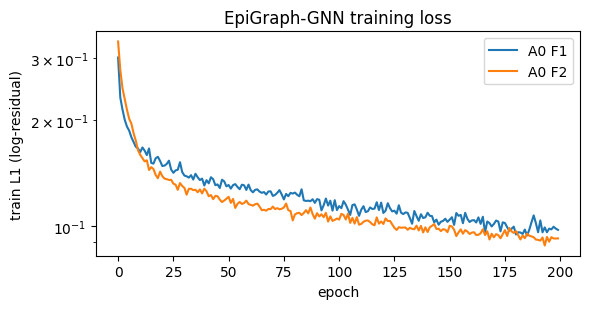

In [ ]:
t0 = time.time()
for name in GNN_CONFIGS:
    for f in FOLDS:
        for s in SEEDS:
            unit(("GNN", name, f, s), lambda: run_gnn(name, f, s))
    print(f"  {name} done ({time.time() - t0:.0f}s)")

plt.figure(figsize=(6, 3.2))
for f in FOLDS:
    plt.plot(CURVES[("A0", f, SEEDS[0])], label=f"A0 {f}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("train L1 (log-residual)"); plt.title("EpiGraph-GNN training loss")
plt.legend(); plt.tight_layout(); plt.savefig(FIGS / "gnn_loss.png", dpi=120); plt.show()


## 19. Temporal Fusion Transformer

In [ ]:
class GRN(nn.Module):
    def __init__(self, d_in, d_hid, d_out):
        super().__init__()
        self.l1, self.l2 = nn.Linear(d_in, d_hid), nn.Linear(d_hid, 2 * d_out)
        self.skip = nn.Linear(d_in, d_out) if d_in != d_out else nn.Identity()
        self.norm, self.drop = nn.LayerNorm(d_out), nn.Dropout(DROPOUT)

    def forward(self, x):
        return self.norm(self.skip(x) + F.glu(self.drop(self.l2(F.elu(self.l1(x)))), -1))


class VarGRN(nn.Module):
    """V independent GRN(d, d, d) — one per input variable — computed in one batched einsum."""
    def __init__(self, V, d):
        super().__init__()
        self.w1, self.b1 = nn.Parameter(torch.randn(V, d, d) / d ** 0.5), nn.Parameter(torch.zeros(V, d))
        self.w2, self.b2 = nn.Parameter(torch.randn(V, d, 2 * d) / d ** 0.5), nn.Parameter(torch.zeros(V, 2 * d))
        self.ln_w, self.ln_b = nn.Parameter(torch.ones(V, d)), nn.Parameter(torch.zeros(V, d))
        self.drop, self.d = nn.Dropout(DROPOUT), d

    def forward(self, e):                      # e [..., V, d]
        h = F.elu(torch.einsum("...vd,vdk->...vk", e, self.w1) + self.b1)
        h = F.glu(self.drop(torch.einsum("...vd,vdk->...vk", h, self.w2) + self.b2), -1)
        return F.layer_norm(e + h, (self.d,)) * self.ln_w + self.ln_b


class CompactTFT(nn.Module):
    """One TFT for all horizons. The horizon enters as a static context vector c_h that conditions
    variable selection (TFT's static-context mechanism), so selection weights are horizon-resolved."""
    def __init__(self, n_static, d=TFT_D):
        super().__init__()
        self.V = 1 + n_static
        self.emb_w, self.emb_b = nn.Parameter(torch.randn(self.V, d)), nn.Parameter(torch.zeros(self.V, d))
        self.var_grn = VarGRN(self.V, d)
        self.h_ctx = nn.Embedding(H, d)
        self.select = GRN(self.V * d + d, d, self.V)
        self.lstm = nn.LSTM(d, d, batch_first=True)
        self.lstm_norm = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, 1, batch_first=True)
        self.post = GRN(2 * d, d, d)
        self.out = nn.Linear(d, 1)
        self.last_w = None

    def forward(self, seq, stat, A=None):
        B, N, L, _ = seq.shape
        x = torch.cat([seq, stat[:, :, None].expand(-1, -1, L, -1)], -1).reshape(B * N, L, self.V)
        e = self.var_grn(x[..., None] * self.emb_w + self.emb_b)       # [BN, L, V, d] per-variable embeddings
        e = e[:, None].expand(-1, H, -1, -1, -1).reshape(B * N * H, L, self.V, -1)   # one copy per horizon
        c = self.h_ctx.weight.repeat(B * N, 1)                          # [BNH, d] horizon context
        w = torch.softmax(self.select(torch.cat([e.flatten(-2), c[:, None].expand(-1, L, -1)], -1)), -1)
        self.last_w = w.detach().reshape(B * N, H, L, self.V)          # variable weights per horizon
        hseq = (w[..., None] * e).sum(-2)
        o, _ = self.lstm(hseq); o = self.lstm_norm(o + hseq)
        a, _ = self.attn(o[:, -1:], o, o)
        return self.out(self.post(torch.cat([a[:, 0] + o[:, -1], c], -1))).reshape(B, N, H)


def var_groups(stat_cols):
    cols = ["ili_history"] + stat_cols
    grp = lambda c: ("ILI history" if c == "ili_history" else "climate" if c in ("temp_tm1", "ah_tm1")
                     else "population" if c == "log_pop" else "season timing" if c.startswith("season")
                     else "genomic")
    return [grp(c) for c in cols]


## 20. Run TFT ± genomic (per horizon) and read out variable importance

In [ ]:
def run_tft(f, variant, name, s):
    fd = get_fold(f, variant)
    groups = np.array(var_groups(fd["stat_cols"]))
    model, _, yhat = fit_predict(CompactTFT(len(fd["stat_cols"])), fd, GRAPHS["asof_L8_16"], s)
    record(f, name, s, fd["te"], yhat)
    w = model.last_w.mean((0, 2)).cpu().numpy()            # [H, V] test-set mean weight per horizon
    for hi, h in enumerate(HORIZONS):
        for gname in np.unique(groups):
            TFT_IMP.append(dict(fold=f, model=name, seed=s, h=h, group=gname, weight=float(w[hi, groups == gname].sum())))


t0 = time.time()
for f in FOLDS:
    for variant, name in [("asof_L8_16", "TFT+gen"), ("none", "TFT-gen")]:
        for s in SEEDS:
            unit(("TFT", name, f, s), lambda: run_tft(f, variant, name, s))
    print(f"  TFT {f} done ({time.time() - t0:.0f}s)")
TFT_IMP_DF = pd.DataFrame(TFT_IMP)


  TFT F1 done (117s)
  TFT F2 done (323s)


## 21. Results

/tmp/ipykernel_436/3292324419.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  MET = PRED.groupby(["fold", "model", "h", "seed"]).apply(point_metrics).reset_index()



=== F1: MAE (mean over seeds), rows = models, cols = horizon ===
h                1      2      3      4      6      8
model                                                
Persistence  0.766  1.061  1.340  1.579  1.872  1.962
LGBM-gen     0.837  1.135  1.441  1.739  2.479  2.780
LGBM+gen     0.912  1.227  1.477  1.810  2.492  2.732
TFT-gen      1.041  1.386  1.774  2.107  2.663  2.991
GNN-A4       1.055  1.395  1.646  1.847  2.218  2.576
GNN-A1       1.133  1.503  1.708  1.839  2.170  2.369
GNN-A3       1.244  1.796  2.132  2.228  2.522  3.038
GNN-A2       1.252  1.779  2.112  2.217  2.458  2.862
GNN-A7       1.292  1.811  2.105  2.173  2.650  3.252
GNN-A6       1.300  1.735  2.140  2.208  2.462  2.986
GNN-A0       1.315  1.798  2.114  2.112  2.393  2.979
GNN-A5       1.412  1.905  2.206  2.228  2.439  2.794
TFT+gen      1.568  1.983  2.315  2.521  3.139  3.434
Seasonal     2.052  2.041  2.032  2.004  1.906  1.739

=== F2: MAE (mean over seeds), rows = models, cols = horizon ===
h   

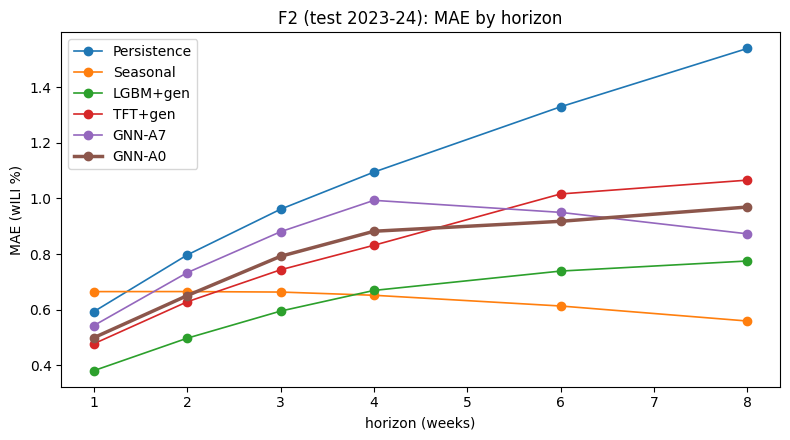

In [ ]:
PRED = pd.concat(PRED_ROWS, ignore_index=True)
assert not PRED.duplicated(["fold", "model", "seed", "h", "T", "region"]).any()
MET = PRED.groupby(["fold", "model", "h", "seed"]).apply(point_metrics).reset_index()
pers = MET[MET["model"] == "Persistence"].set_index(["fold", "h"])["MAE"]
MET["skill"] = 1 - MET["MAE"] / MET.set_index(["fold", "h"]).index.map(pers)

summary = MET.groupby(["fold", "model", "h"])[["MAE", "RMSE", "PCC", "skill"]].mean().reset_index()
for f in FOLDS:
    print(f"\n=== {f}: MAE (mean over seeds), rows = models, cols = horizon ===")
    print(summary[summary["fold"] == f].pivot(index="model", columns="h", values="MAE").round(3).sort_values(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
s2 = summary[summary["fold"] == "F2"]
for mdl in ["Persistence", "Seasonal", "Chronos", "LGBM+gen", "TFT+gen", "GNN-A7", "GNN-A0"]:
    g = s2[s2["model"] == mdl]
    if len(g):
        ax.plot(g["h"], g["MAE"], marker="o", lw=2.5 if mdl == "GNN-A0" else 1.2, label=mdl)
ax.set_xlabel("horizon (weeks)"); ax.set_ylabel("MAE (wILI %)"); ax.set_title("F2 (test 2023-24): MAE by horizon")
ax.legend(); plt.tight_layout(); plt.savefig(FIGS / "mae_by_horizon.png", dpi=120); plt.show()


## 22. Conformal prediction wrapper

In [ ]:
cov_rows, INTERVALS = [], []
i50, i90 = WIS_ALPHAS.index(0.5), WIS_ALPHAS.index(0.1)
for (mdl, seed, h), te in PRED[PRED["fold"] == "F2"].groupby(["model", "seed", "h"]):
    cal = PRED[(PRED["fold"] == "F1") & (PRED["model"] == mdl) & (PRED["seed"] == seed) & (PRED["h"] == h)]
    if cal.empty:
        continue
    lo, hi = conformal(cal, te)
    y = te["y"].to_numpy()
    w = wis(y, te["yhat"].to_numpy(), lo, hi, WIS_ALPHAS)
    in50 = (lo[:, i50] <= y) & (y <= hi[:, i50]); in90 = (lo[:, i90] <= y) & (y <= hi[:, i90])
    hg = te["has_gen"].to_numpy()
    cov_rows.append(dict(fold="F2", model=mdl, seed=seed, h=h, WIS=w.mean(), cov50=in50.mean(), cov90=in90.mean(),
                         cov90_gen=in90[hg].mean(), cov90_nogen=in90[~hg].mean()))
    INTERVALS.append(te[["model", "seed", "h", "T", "region"]].assign(
        **{f"lo_{a}": lo[:, k] for k, a in enumerate(WIS_ALPHAS)}, **{f"hi_{a}": hi[:, k] for k, a in enumerate(WIS_ALPHAS)}))
COV = pd.DataFrame(cov_rows)
MET = MET.merge(COV, on=["fold", "model", "seed", "h"], how="left")

for f, te_y, q in STATE["chronos"]:                 # Chronos' own quantiles, for comparison
    if f != "F2":
        continue
    al = [0.2, 0.4, 0.6, 0.8]                      # central intervals from levels 0.1..0.9
    lo = np.stack([q[..., CHRONOS_Q.index(round(a / 2, 1))] for a in al], -1).reshape(-1, len(HORIZONS), 4)
    hi = np.stack([q[..., CHRONOS_Q.index(round(1 - a / 2, 1))] for a in al], -1).reshape(-1, len(HORIZONS), 4)
    med = q[..., CHRONOS_Q.index(0.5)].reshape(-1, len(HORIZONS)); yy = te_y.reshape(-1, len(HORIZONS))
    print("Chronos native-quantile WIS by h:",
          {h: round(wis(yy[:, k], med[:, k], lo[:, k], hi[:, k], al).mean(), 3) for k, h in enumerate(HORIZONS)})

print(COV.groupby(["model", "h"])[["WIS", "cov50", "cov90", "cov90_gen", "cov90_nogen"]].mean()
      .unstack("h")["WIS"].round(3).sort_values(1).to_string())
print("\nMean 90% coverage (target 0.90):\n", COV.groupby("model")[["cov50", "cov90", "cov90_gen", "cov90_nogen"]].mean().round(3).to_string())


h                1      2      3      4      6      8
model                                                
LGBM+gen     0.278  0.370  0.455  0.544  0.763  0.776
LGBM-gen     0.288  0.374  0.456  0.539  0.773  0.815
TFT-gen      0.358  0.469  0.574  0.685  0.871  0.963
GNN-A4       0.374  0.485  0.592  0.695  0.877  0.966
Persistence  0.378  0.505  0.610  0.702  0.856  0.981
GNN-A1       0.385  0.504  0.599  0.680  0.857  0.949
GNN-A3       0.407  0.542  0.607  0.675  0.892  1.059
GNN-A2       0.412  0.522  0.597  0.691  0.913  1.027
GNN-A7       0.429  0.582  0.690  0.769  0.880  0.986
GNN-A0       0.430  0.555  0.652  0.718  0.902  1.053
GNN-A5       0.441  0.591  0.689  0.772  0.931  1.000
TFT+gen      0.442  0.568  0.673  0.746  0.930  0.985
GNN-A6       0.446  0.571  0.675  0.741  0.931  1.013
Seasonal     0.649  0.635  0.626  0.612  0.571  0.515

Mean 90% coverage (target 0.90):
              cov50  cov90  cov90_gen  cov90_nogen
model                                            
G

## 23. does genomic data improve the forecast, and at which horizons?


/tmp/ipykernel_436/1187931203.py:65: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_seed = sel.groupby(["model", "seed"]).apply(lambda g: (g["yhat"] - g["y"]).abs().mean()).unstack(0)
/tmp/ipykernel_436/1187931203.py:65: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_seed = sel.groupby(["model", "seed"]).apply(lambda g: (g["yhat"] - g["y"]).abs().mean()).unstack(0)
/tmp/ipykernel_436/1187931203.py:65:

fold  h  granger_p_holm_min  te_p_holm_min  GNN_delta  GNN_sd           GNN_ci  GNN_helps  TFT_delta  TFT_sd           TFT_ci  TFT_helps  LGBM_delta  LGBM_sd          LGBM_ci  LGBM_helps            verdict
  F1  1               0.973         0.0240    -0.1820  0.1957 [-0.374, -0.001]      False    -0.5267  0.3089 [-0.839, -0.244]      False     -0.0753   0.0116 [-0.174, -0.004]       False no measurable gain
  F1  2               0.973         0.3776    -0.2946  0.3156  [-0.801, 0.114]      False    -0.5977  0.3353 [-0.983, -0.247]      False     -0.0929   0.0243 [-0.218, -0.005]       False no measurable gain
  F1  3               1.000         0.0180    -0.4061  0.3425  [-1.146, 0.207]      False    -0.5408  0.3355 [-0.908, -0.224]      False     -0.0357   0.0214  [-0.178, 0.060]       False no measurable gain
  F1  4               1.000         0.0120    -0.2727  0.2826  [-0.702, 0.144]      False    -0.4140  0.2771 [-0.780, -0.072]      False     -0.0712   0.0372  [-0.172, 0.005]  

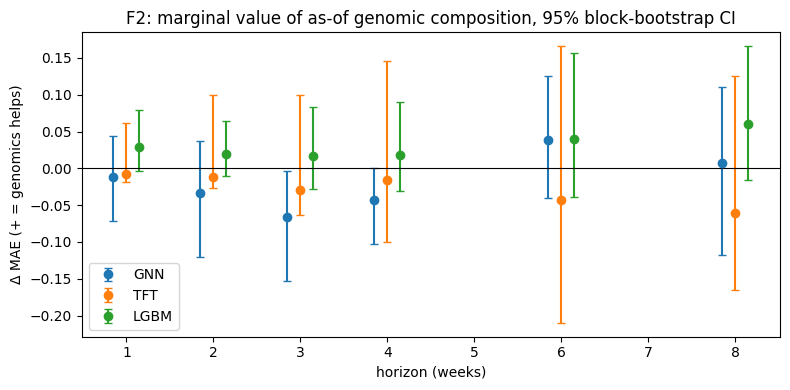

In [ ]:
PAIRS = {"GNN": ("GNN-A1", "GNN-A0"), "TFT": ("TFT-gen", "TFT+gen"), "LGBM": ("LGBM-gen", "LGBM+gen")}
rng = np.random.default_rng(0)
vrows = []
for f in FOLDS:
    for h in HORIZONS:
        row = dict(fold=f, h=h)
        ca = CAUSAL[(CAUSAL["source"] == "asof_L8_16") & (CAUSAL["h"] == h)]
        row["granger_p_holm_min"] = ca["granger_p_holm"].min(); row["te_p_holm_min"] = ca["te_p_holm"].min()
        n_help = 0
        for arch, (b, full) in PAIRS.items():
            g = genomic_gain(PRED, f, b, full, h, rng)
            row.update({f"{arch}_delta": g["delta"], f"{arch}_sd": g["seed_sd"],
                        f"{arch}_ci": f"[{g['ci_lo']:.3f}, {g['ci_hi']:.3f}]", f"{arch}_helps": g["helps"]})
            n_help += g["helps"]
        row["verdict"] = "GENOMICS HELPS" if (row["granger_p_holm_min"] < 0.05 and n_help >= 2) else "no measurable gain"
        vrows.append(row)
VERDICT = pd.DataFrame(vrows)
VERDICT.to_csv(RESULTS / "genomic_verdict.csv", index=False)
print(VERDICT.round(4).to_string(index=False))

for f in FOLDS:   # H1: does the gain grow with horizon?
    v = VERDICT[VERDICT["fold"] == f]
    print(f"{f} H1 trend, Spearman ρ(h, Δ):",
          {a: round(spearmanr(v["h"], v[f"{a}_delta"]).statistic, 2) for a in PAIRS})

fig, ax = plt.subplots(figsize=(8, 4))
v = VERDICT[VERDICT["fold"] == "F2"]
for k, arch in enumerate(PAIRS):
    lo_hi = np.array([[float(x) for x in c.strip("[]").split(",")] for c in v[f"{arch}_ci"]])
    xs = v["h"] + (k - 1) * 0.15
    ax.errorbar(xs, v[f"{arch}_delta"], yerr=[v[f"{arch}_delta"] - lo_hi[:, 0], lo_hi[:, 1] - v[f"{arch}_delta"]],
                fmt="o", capsize=3, label=arch)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("horizon (weeks)"); ax.set_ylabel("Δ MAE (+ = genomics helps)")
ax.set_title("F2: marginal value of as-of genomic composition, 95% block-bootstrap CI"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "genomic_gain_by_horizon.png", dpi=120); plt.show()


## 24. Hypothesis

H2 — genomic relation (A2 = no genomic edges):
 h           1      2      3      4      6      8
model                                           
GNN-A0  0.500  0.651  0.792  0.882  0.918  0.969
GNN-A2  0.498  0.625  0.708  0.796  0.849  0.899

H3 — coverage-aware vs zero-fill (A3):
 h           1      2      3      4      6      8
model                                           
GNN-A0  0.500  0.651  0.792  0.882  0.918  0.969
GNN-A3  0.466  0.587  0.672  0.731  0.833  0.932

H4 — oracle (A4, leaky ceiling) vs as-of L8-16 (A0) vs L4-12 (A5):
 h           1      2      3      4      6      8
model                                           
GNN-A4  0.473  0.609  0.732  0.832  0.943  0.903
GNN-A0  0.500  0.651  0.792  0.882  0.918  0.969
GNN-A5  0.500  0.693  0.839  0.930  0.928  0.921

Graph control — real (A0) vs density-matched random (A6) vs no graph (A7):
 h           1      2      3      4      6      8
model                                           
GNN-A0  0.500  0.651  0.792  0

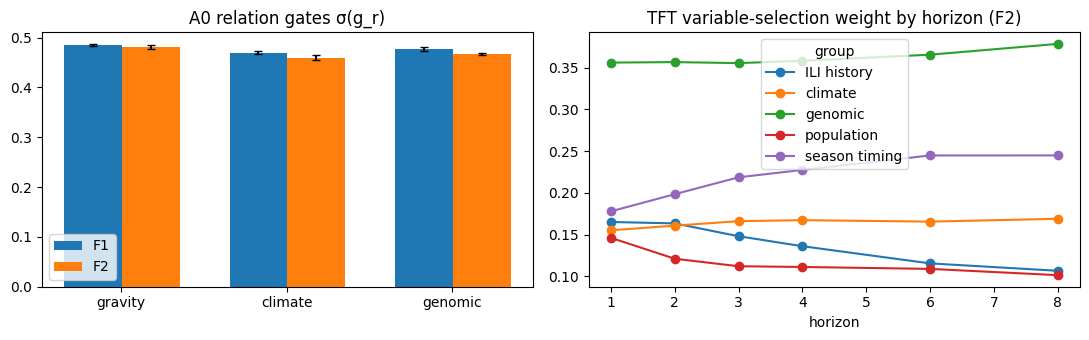

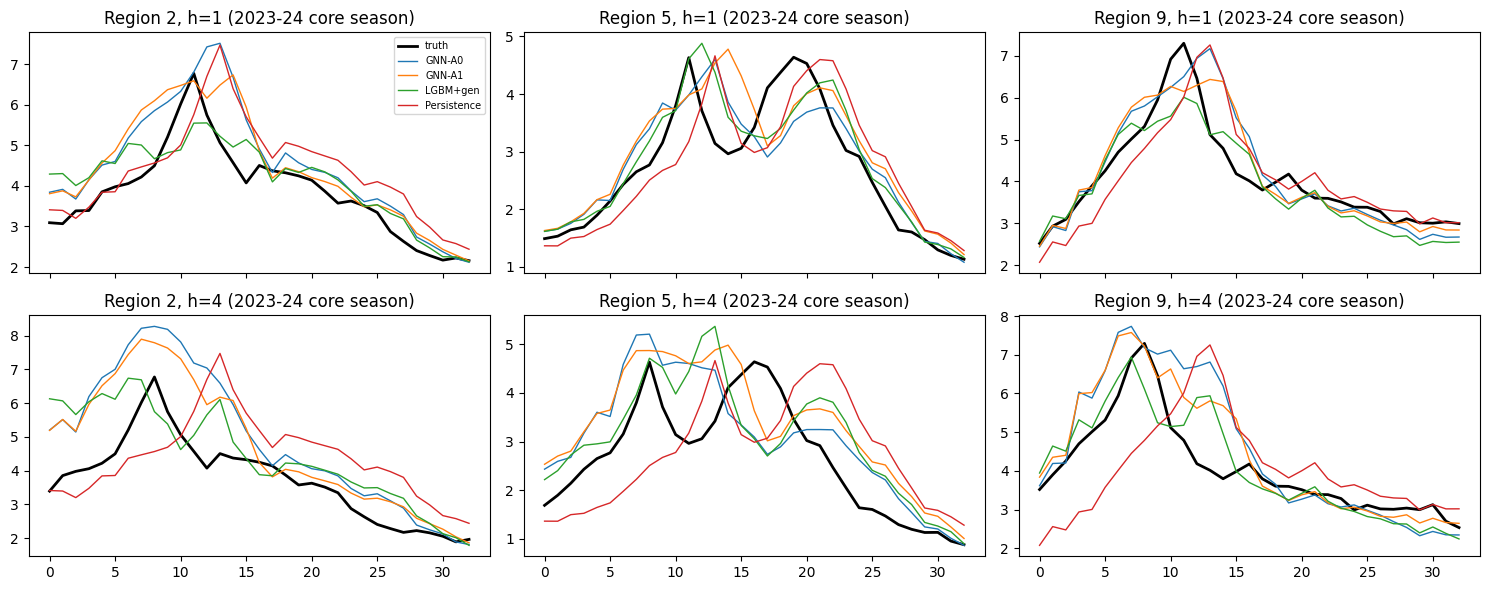

In [ ]:
def mae_table(models, fold="F2"):
    s = summary[(summary["fold"] == fold) & summary["model"].isin(models)]
    return s.pivot(index="model", columns="h", values="MAE").reindex(models).round(3)

print("H2 — genomic relation (A2 = no genomic edges):\n", mae_table(["GNN-A0", "GNN-A2"]).to_string())
print("\nH3 — coverage-aware vs zero-fill (A3):\n", mae_table(["GNN-A0", "GNN-A3"]).to_string())
print("\nH4 — oracle (A4, leaky ceiling) vs as-of L8-16 (A0) vs L4-12 (A5):\n", mae_table(["GNN-A4", "GNN-A0", "GNN-A5"]).to_string())
print("\nGraph control — real (A0) vs density-matched random (A6) vs no graph (A7):\n", mae_table(["GNN-A0", "GNN-A6", "GNN-A7"]).to_string())

GATES_DF = pd.DataFrame(GATES)
gsum = GATES_DF.groupby(["config", "fold", "relation"])["gate"].agg(["mean", "std"]).round(3)
print("\nLearned relation gates σ(g_r):\n", gsum.loc[["A0"]].to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ga = GATES_DF[GATES_DF["config"] == "A0"].groupby(["fold", "relation"])["gate"].agg(["mean", "std"]).reset_index()
for k, f in enumerate(FOLDS):
    g = ga[ga["fold"] == f].set_index("relation").reindex(RELATIONS)
    axes[0].bar(np.arange(3) + k * 0.35, g["mean"], 0.35, yerr=g["std"], label=f, capsize=3)
axes[0].set_xticks(np.arange(3) + 0.17, RELATIONS); axes[0].set_title("A0 relation gates σ(g_r)"); axes[0].legend()
ti = TFT_IMP_DF[(TFT_IMP_DF["model"] == "TFT+gen") & (TFT_IMP_DF["fold"] == "F2")].groupby(["h", "group"])["weight"].mean().unstack()
ti.plot(ax=axes[1], marker="o"); axes[1].set_title("TFT variable-selection weight by horizon (F2)"); axes[1].set_xlabel("horizon")
plt.tight_layout(); plt.savefig(FIGS / "gates_and_tft_importance.png", dpi=120); plt.show()

# example forecasts: 3 regions, h = 1 and 4, seed-averaged
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
pa = PRED[(PRED["fold"] == "F2")].groupby(["model", "h", "region", "T"])[["y", "yhat"]].mean().reset_index()
for i, h in enumerate([1, 4]):
    for j, r in enumerate([2, 5, 9]):
        ax = axes[i, j]
        g = pa[(pa["h"] == h) & (pa["region"] == r)]
        base = g[g["model"] == "GNN-A0"]
        ax.plot(range(len(base)), base["y"], "k-", lw=2, label="truth")
        for mdl in ["GNN-A0", "GNN-A1", "LGBM+gen", "Persistence"]:
            gm = g[g["model"] == mdl]; ax.plot(range(len(gm)), gm["yhat"], lw=1, label=mdl)
        ax.set_title(f"Region {r}, h={h} (2023-24 core season)")
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.savefig(FIGS / "example_forecasts.png", dpi=120); plt.show()


In [ ]:
PRED.to_csv(RESULTS / "predictions.csv.gz", index=False)
if INTERVALS:
    pd.concat(INTERVALS).to_csv(RESULTS / "intervals.csv.gz", index=False)
MET.to_csv(RESULTS / "metrics.csv", index=False)
GATES_DF.to_csv(RESULTS / "gates.csv", index=False)
TFT_IMP_DF.to_csv(RESULTS / "tft_importance.csv", index=False)

# Compute INPUT_MD5 if it was not defined during setup
if "INPUT_MD5" not in globals():
    INPUT_MD5 = {k: hashlib.md5(Path(p).read_bytes()).hexdigest() for k, p in FILES.items() if Path(p).exists()}

run_info = dict(timestamp=time.strftime("%Y-%m-%d %H:%M:%S"), quick_mode=QUICK, input_md5=INPUT_MD5,
                versions={"python": sys.version.split()[0], "torch": torch.__version__, "pandas": pd.__version__,
                          "numpy": np.__version__, "lightgbm": lgb.__version__, "statsmodels": sm.__version__},
                config={k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()})
(RESULTS / "run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print("Saved to", RESULTS)
for p in sorted(RESULTS.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(RESULTS)}  ({p.stat().st_size / 1024:.0f} KB)")

Saved to /content/results/phase3
  causality.csv  (3 KB)
  checkpoint.pkl  (14242 KB)
  figures/example_forecasts.png  (304 KB)
  figures/gates_and_tft_importance.png  (60 KB)
  figures/genomic_coverage.png  (24 KB)
  figures/genomic_gain_by_horizon.png  (42 KB)
  figures/gnn_loss.png  (45 KB)
  figures/graphs_example.png  (22 KB)
  figures/mae_by_horizon.png  (71 KB)
  figures/wili_by_region.png  (202 KB)
  gates.csv  (7 KB)
  genomic_verdict.csv  (3 KB)
  intervals.csv.gz  (23093 KB)
  metrics.csv  (88 KB)
  models/EpiGraphGNN-A0/F1/seed0.pt  (223 KB)
  models/EpiGraphGNN-A0/F1/seed1.pt  (223 KB)
  models/EpiGraphGNN-A0/F1/seed2.pt  (223 KB)
  models/EpiGraphGNN-A0/F1/seed3.pt  (223 KB)
  models/EpiGraphGNN-A0/F1/seed4.pt  (223 KB)
  models/EpiGraphGNN-A0/F2/seed0.pt  (223 KB)
  models/EpiGraphGNN-A0/F2/seed1.pt  (223 KB)
  models/EpiGraphGNN-A0/F2/seed2.pt  (223 KB)
  models/EpiGraphGNN-A0/F2/seed3.pt  (223 KB)
  models/EpiGraphGNN-A0/F2/seed4.pt  (223 KB)
  predictions.csv.gz  (332

In [ ]:
f2 = summary[summary["fold"] == "F2"].pivot(index="model", columns="h", values="MAE")
best = f2.idxmin()
print("Best model by MAE per horizon (F2):", best.to_dict())
print("EpiGraph-GNN (A0) skill vs persistence (F2):",
      summary[(summary["fold"] == "F2") & (summary["model"] == "GNN-A0")].set_index("h")["skill"].round(3).to_dict())
print("Genomic verdict (F2):", VERDICT[VERDICT["fold"] == "F2"].set_index("h")["verdict"].to_dict())
print("Genomic verdict (F1):", VERDICT[VERDICT["fold"] == "F1"].set_index("h")["verdict"].to_dict())
print("A0 gates (F2):", GATES_DF[(GATES_DF["config"] == "A0") & (GATES_DF["fold"] == "F2")].groupby("relation")["gate"].mean().round(3).to_dict())
print("\nNext: Phase 4 = extend GNN_CONFIGS (composition representations, KAN row); "
      "Phase 5 = per-tier conformal correction using intervals.csv.gz.")


Best model by MAE per horizon (F2): {1: 'LGBM+gen', 2: 'LGBM+gen', 3: 'LGBM+gen', 4: 'Seasonal', 6: 'Seasonal', 8: 'Seasonal'}
EpiGraph-GNN (A0) skill vs persistence (F2): {1: 0.158, 2: 0.183, 3: 0.176, 4: 0.194, 6: 0.31, 8: 0.37}
Genomic verdict (F2): {1: 'no measurable gain', 2: 'no measurable gain', 3: 'no measurable gain', 4: 'no measurable gain', 6: 'no measurable gain', 8: 'no measurable gain'}
Genomic verdict (F1): {1: 'no measurable gain', 2: 'no measurable gain', 3: 'no measurable gain', 4: 'no measurable gain', 6: 'no measurable gain', 8: 'no measurable gain'}
A0 gates (F2): {'climate': 0.46, 'genomic': 0.467, 'gravity': 0.48}

Next: Phase 4 = extend GNN_CONFIGS (composition representations, KAN row); Phase 5 = per-tier conformal correction using intervals.csv.gz.
